## Downstream Analysis

Note: Please run the notebook Patch_PatchEmbeddings_Unimodel.ipynb before this notebook, as it is responsible for creating the patches, patch embeddings and metadata needed for this notebook.

**PCA (Principal Component Analysis)**:  
We run PCA with a reduction to 50 components (UNI model has 1536 features).  
Results are stored in adata.obsm["X_pca"] (PCA components (n x 50)).

**UMAP (Uniform Manifold Approximation and Projection for Dimension Reduction)**:  


**Leiden Clustering**:

*Please also note*: if you have already run the initial PCA and filtered but would like to rerun leiden or other methods, run the following 3 cells and then skip to step 3. 
BUT: be aware that if you have also already performed step 3 and now rerun step 3 on the file `filtered_WSI_patch_embeddings.h5ad`, this might skew the results.

In [ ]:
import anndata as ad
from tqdm import tqdm
import scanpy as sc
import os
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import numpy as np
import seaborn as sns
import random

['CRC_P1', 'CRC_P2', 'CRC_P5', 'Normal_P3', 'Normal_P5']
Categories (5, object): ['CRC_P1', 'CRC_P2', 'CRC_P5', 'Normal_P3', 'Normal_P5']


In [ ]:
patch_base_folder = "patches"
leiden_res = [0.2, 0.5, 1.0, 2.0] # set the resolutions you want to use for leiden clustering
chosen_resolution = 0.5 # Choose the leiden resolution you want to use for filtering

In [ ]:
### Helper functions for clustering and plotting

# Leiden Clustering
def run_leiden(adata, leiden_res):
    for res in leiden_res:
        key = f"leiden_{res}"
        sc.tl.leiden(adata, resolution=res, key_added=key)


def plot_patches(adata, res, patch_base_folder="patches"):

    umap_coords = adata.obsm["X_umap"]
    clusters = adata.obs[f"leiden_{res}"].astype(str)  # Convert Leiden clusters to strings
    sample_ids = adata.obs["Slide_ID"].astype(str)  # Get patient/sample IDs
    patch_ids = adata.obs["Patch_ID"].astype(str)  # Get patch file names


    def getImage(path, zoom=0.15):  # Adjust zoom level for patch size
        return OffsetImage(plt.imread(path), zoom=zoom)


    fig, ax = plt.subplots(figsize=(18, 18))
    ax.scatter(umap_coords[:, 0], umap_coords[:, 1], c="white", alpha=1, edgecolors="w", label="Cells")


    for cluster in sorted(clusters.unique()):

        cluster_indices = np.where(clusters == cluster)[0]
        if len(cluster_indices) == 0:
            continue

        selected_indices = random.sample(list(cluster_indices), min(30, len(cluster_indices)))

    
        for i in selected_indices:
            x0, y0 = umap_coords[i]  # Get UMAP position
            sample_id = sample_ids[i]  # Get Sample ID
            patch_id = patch_ids[i]  # Get Patch file name

            patch_folder = os.path.join(patch_base_folder, sample_id)
            patch_path = os.path.join(patch_folder, patch_id)

            if not os.path.exists(patch_path):
                print(f"Warning: Missing patch {patch_path}")
                continue


            ab = AnnotationBbox(getImage(patch_path), (x0, y0), frameon=False, box_alignment=(0.5, 0.5), pad=0)
            ax.add_artist(ab)


        avg_x, avg_y = np.mean(umap_coords[cluster_indices], axis=0)
        ax.annotate(f"Cluster {cluster}", (avg_x, avg_y), fontsize=16, ha="center", color="black", weight="bold")


    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    ax.set_title("UMAP with 10 Example Patches per Cluster")
    #fig.savefig('Umap_patches.pdf')


# 1. Clustering
In this section we perform clustering using methods such as leiden and PCA. 
The second step will then follow up with manually filtering out patches that do not include any tissue. 
Step 3 then reruns the clustering and plots the new clusters.

In [ ]:
adata = sc.read("metadata/WSI_patch_embeddings.h5ad")

print(adata.obs["Slide_ID"].unique()) # make sure we have as many unique slide IDs as we have patch folders and names fit

In [3]:
# PCA
sc.pp.pca(adata, n_comps=50)
sc.pp.neighbors(adata, use_rep="X_pca")

/home/charlottewolf/miniconda3/envs/uni/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# UMAP + leiden
sc.tl.umap(adata)

In [ ]:
# Leiden with resolution set in initial cell
run_leiden(adata, leiden_res)

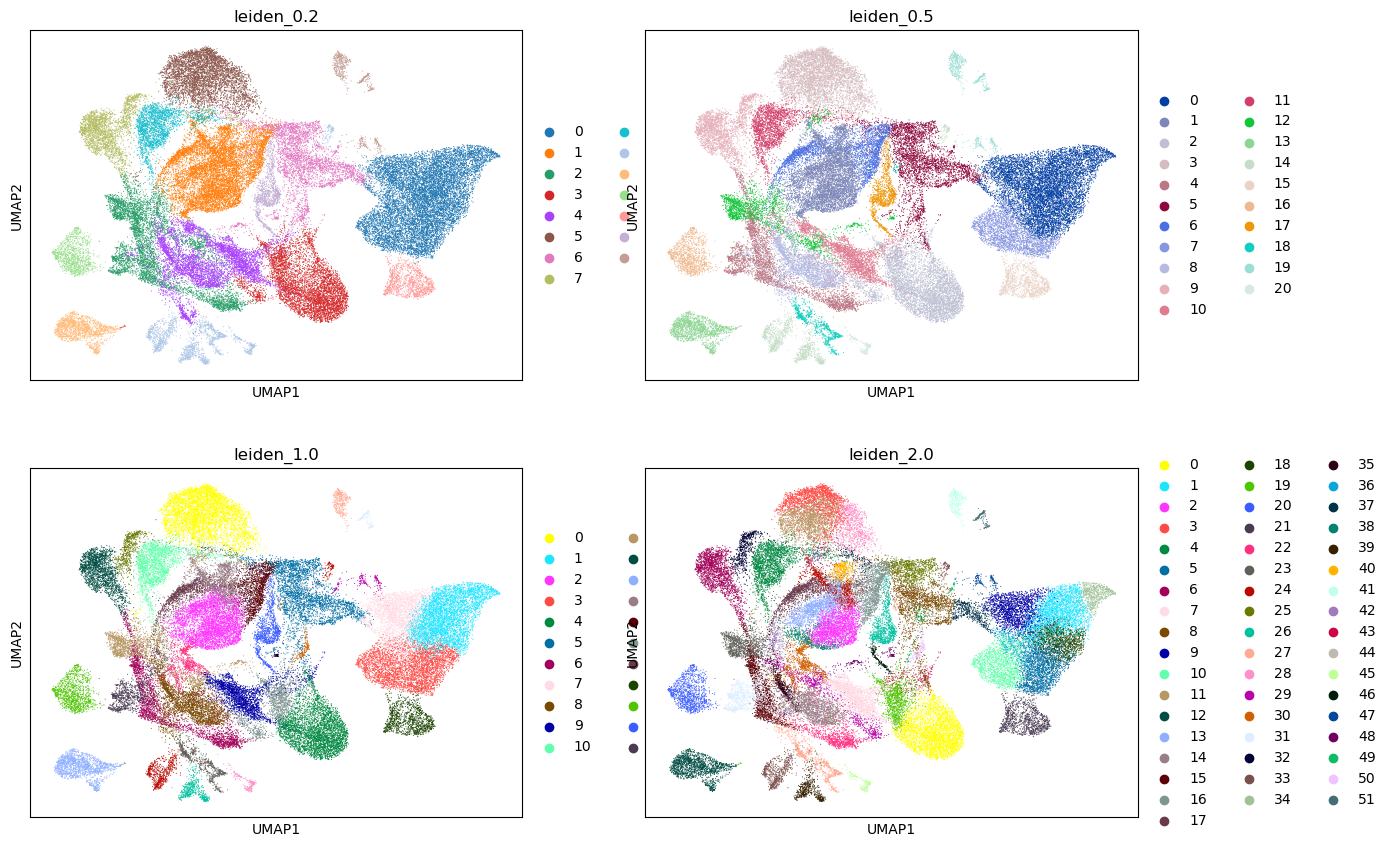

In [6]:
sc.pl.umap(adata, color=["leiden_0.2", "leiden_0.5", "leiden_1.0", "leiden_2.0"], ncols=2)

**Plotting the Clusters with examplary patches**  
We can use these cluster patches to filter out clusters that combine the background and save foreground images to a new adata object.

/tmp/ipykernel_6633/3652130149.py:36: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  sample_id = sample_ids[i]  # Get Sample ID
/tmp/ipykernel_6633/3652130149.py:37: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  patch_id = patch_ids[i]  # Get Patch file name


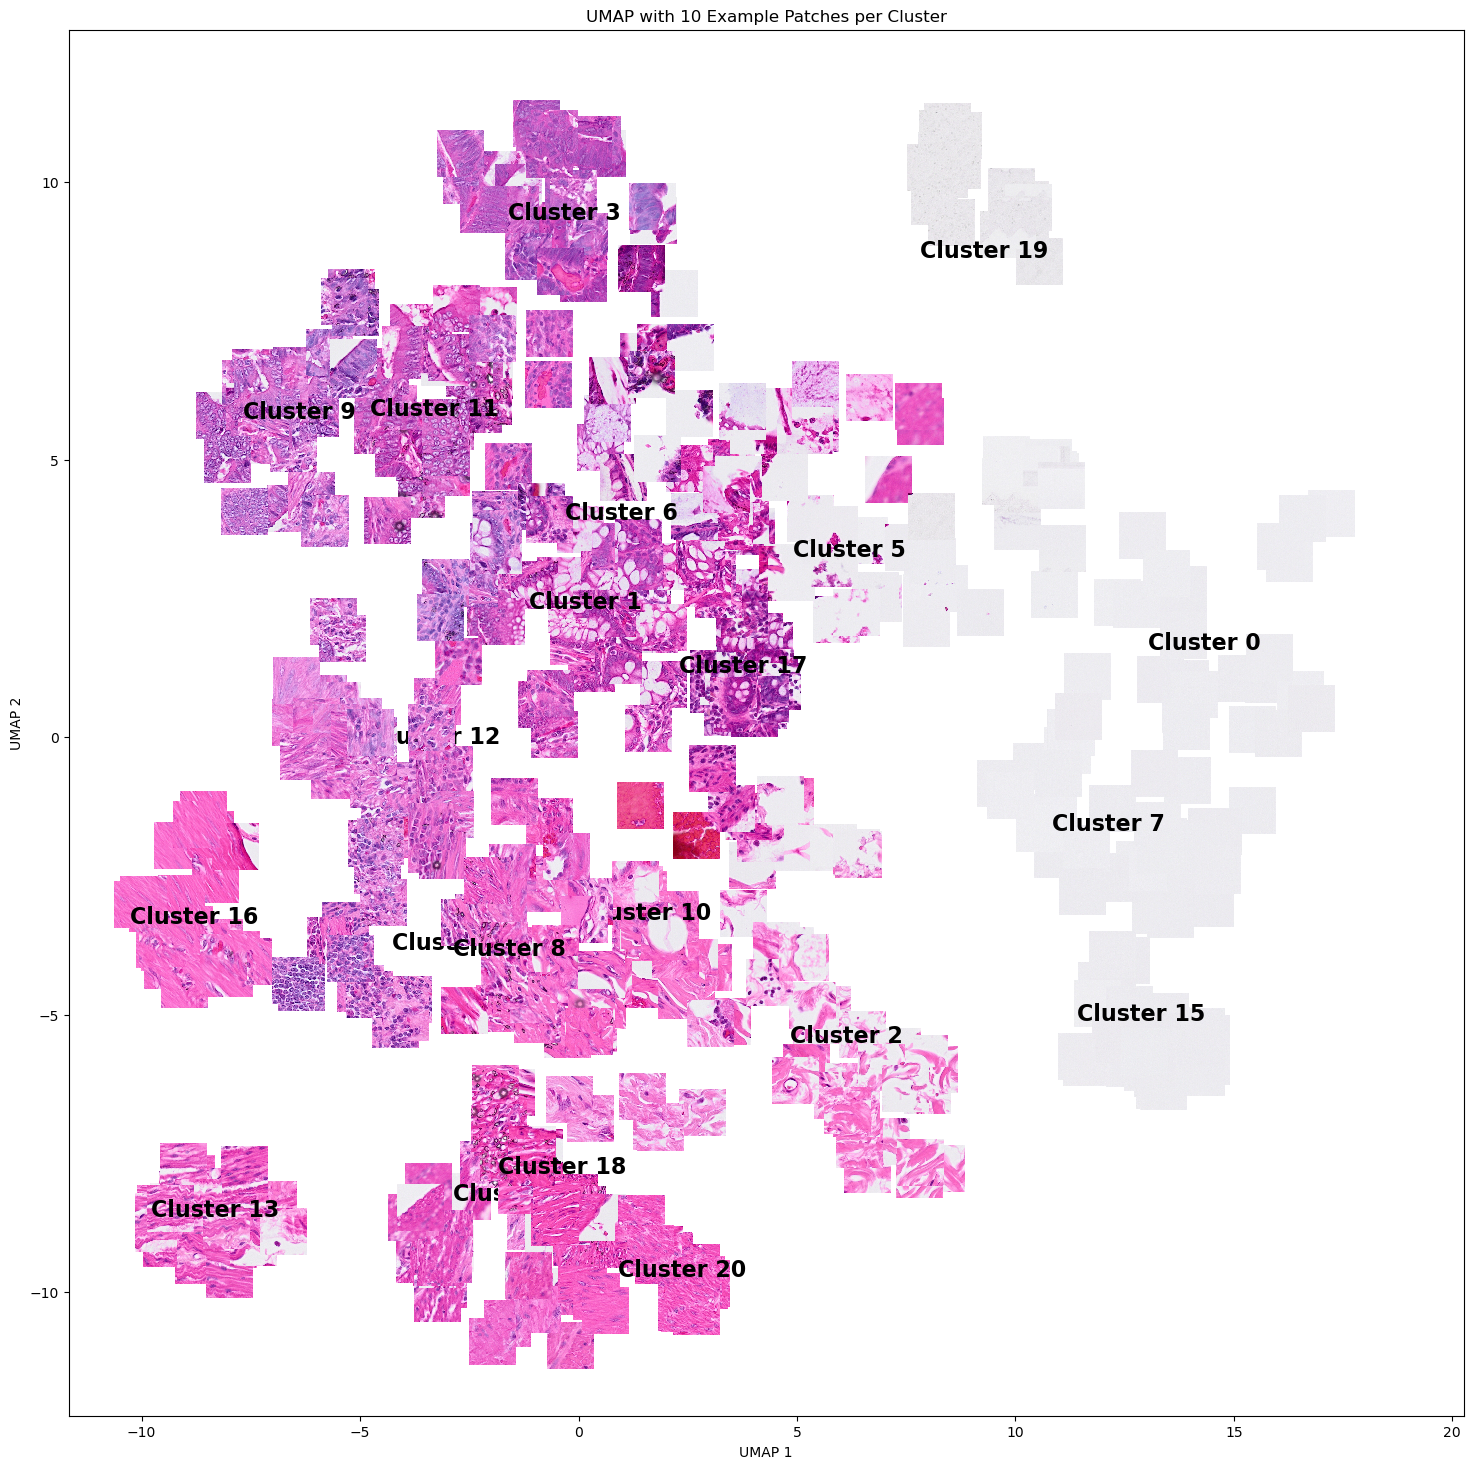

In [ ]:
plot_patches(adata, chosen_resolution, patch_base_folder)

In [ ]:
adata.write("metadata/WSI_patch_embeddings.h5ad")

## 2. Filtering clusters with no tisssue 
In the following, we filter out clusters that have no tissue in it.
Note, that there can be clusters where there seems to be some patches with and without tissues.  
We then re-run PCA, the neighbor graph, UMAP and leiden and store the new filtered AnnData Object in the metadata folder as "filtered_WSI_patch_embeddings.h5ad".

Use the following cell to filter out any cluster that only has background information. 
Adapt `remove_clusters` to the clusters you want to remove before running the cell.    
This also stores the unfiltered patch embeddings in the patch folder for each person. 

In [9]:
people = adata.obs["Slide_ID"].unique()
remove_clusters = ['0', '7', '15', '19'] # Adapt based on the clusters you want to remove. See plot above.

for person in people:
    patient_adata = adata[adata.obs["Slide_ID"] == person].copy()
    if not os.path.exists(f"{patch_base_folder}/{person}"):
        os.makedirs(f"{patch_base_folder}/{person}")
    patient_adata.write(f"{patch_base_folder}/{person}/unfiltered_patch_embeddings.h5ad")
adata_filter=adata[~adata.obs[f"leiden_{chosen_resolution}"].isin(remove_clusters)].copy()
adata_filter.write("metadata/filtered_WSI_patch_embeddings.h5ad")

**Note**: The cell below does not necessarily need to be run if you intend to run Step 3 righat after Step 2.

In [ ]:
adata_filter.write("metadata/filtered_WSI_patch_embeddings.h5ad")

# 3. Re-running clustering and plot new clusters
Now we only plot clusters with tissue in it. 
For this, we also rerun clustering methods such as PCA and leiden on only the sub-selection of patches that are the result of the previous step. 

In [ ]:
import os
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import numpy as np
import seaborn as sns
import random

In [ ]:
# Run this cell if you did not run step 1 during this session and have already created the filtered patch embeddings. 
adata_filter = sc.read_h5ad("metadata/filtered_WSI_patch_embeddings.h5ad")
adata_filter.obs
patch_base_folder = "patches"

Remove old leiden information, then rerun PCA, set neighbors and then run UMAP and leiden again. 
Finally, we plot the UMAP graph again.

In [ ]:
# Delete leiden columns
for res in leiden_res:
    if f"leiden_{res}" in adata_filter.obs:
        del adata_filter.obs[f"leiden_{res}"]
    if f"leiden_{res}" in adata_filter.uns:
        del adata_filter.uns[f"leiden_{res}"]


# Re-run PCA and leiden on filtered patch embeddings
sc.pp.pca(adata_filter, n_comps=50)
sc.pp.neighbors(adata_filter, use_rep="X_pca")
sc.tl.umap(adata_filter)

run_leiden(adata_filter, leiden_res)

sc.pl.umap(adata_filter, color=["leiden_0.2", "leiden_0.5", "leiden_1.0", "leiden_2.0"], ncols=2)

In [13]:
print(adata_filter.obs["Slide_ID"].unique())  # Check unique slide IDs in the filtered data

['CRC_P1', 'CRC_P2', 'CRC_P5', 'Normal_P3', 'Normal_P5']
Categories (5, object): ['CRC_P1', 'CRC_P2', 'CRC_P5', 'Normal_P3', 'Normal_P5']


/tmp/ipykernel_35502/617063563.py:37: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  sample_id = sample_ids[i]  # Get Sample ID
/tmp/ipykernel_35502/617063563.py:38: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  patch_id = patch_ids[i]  # Get Patch file name


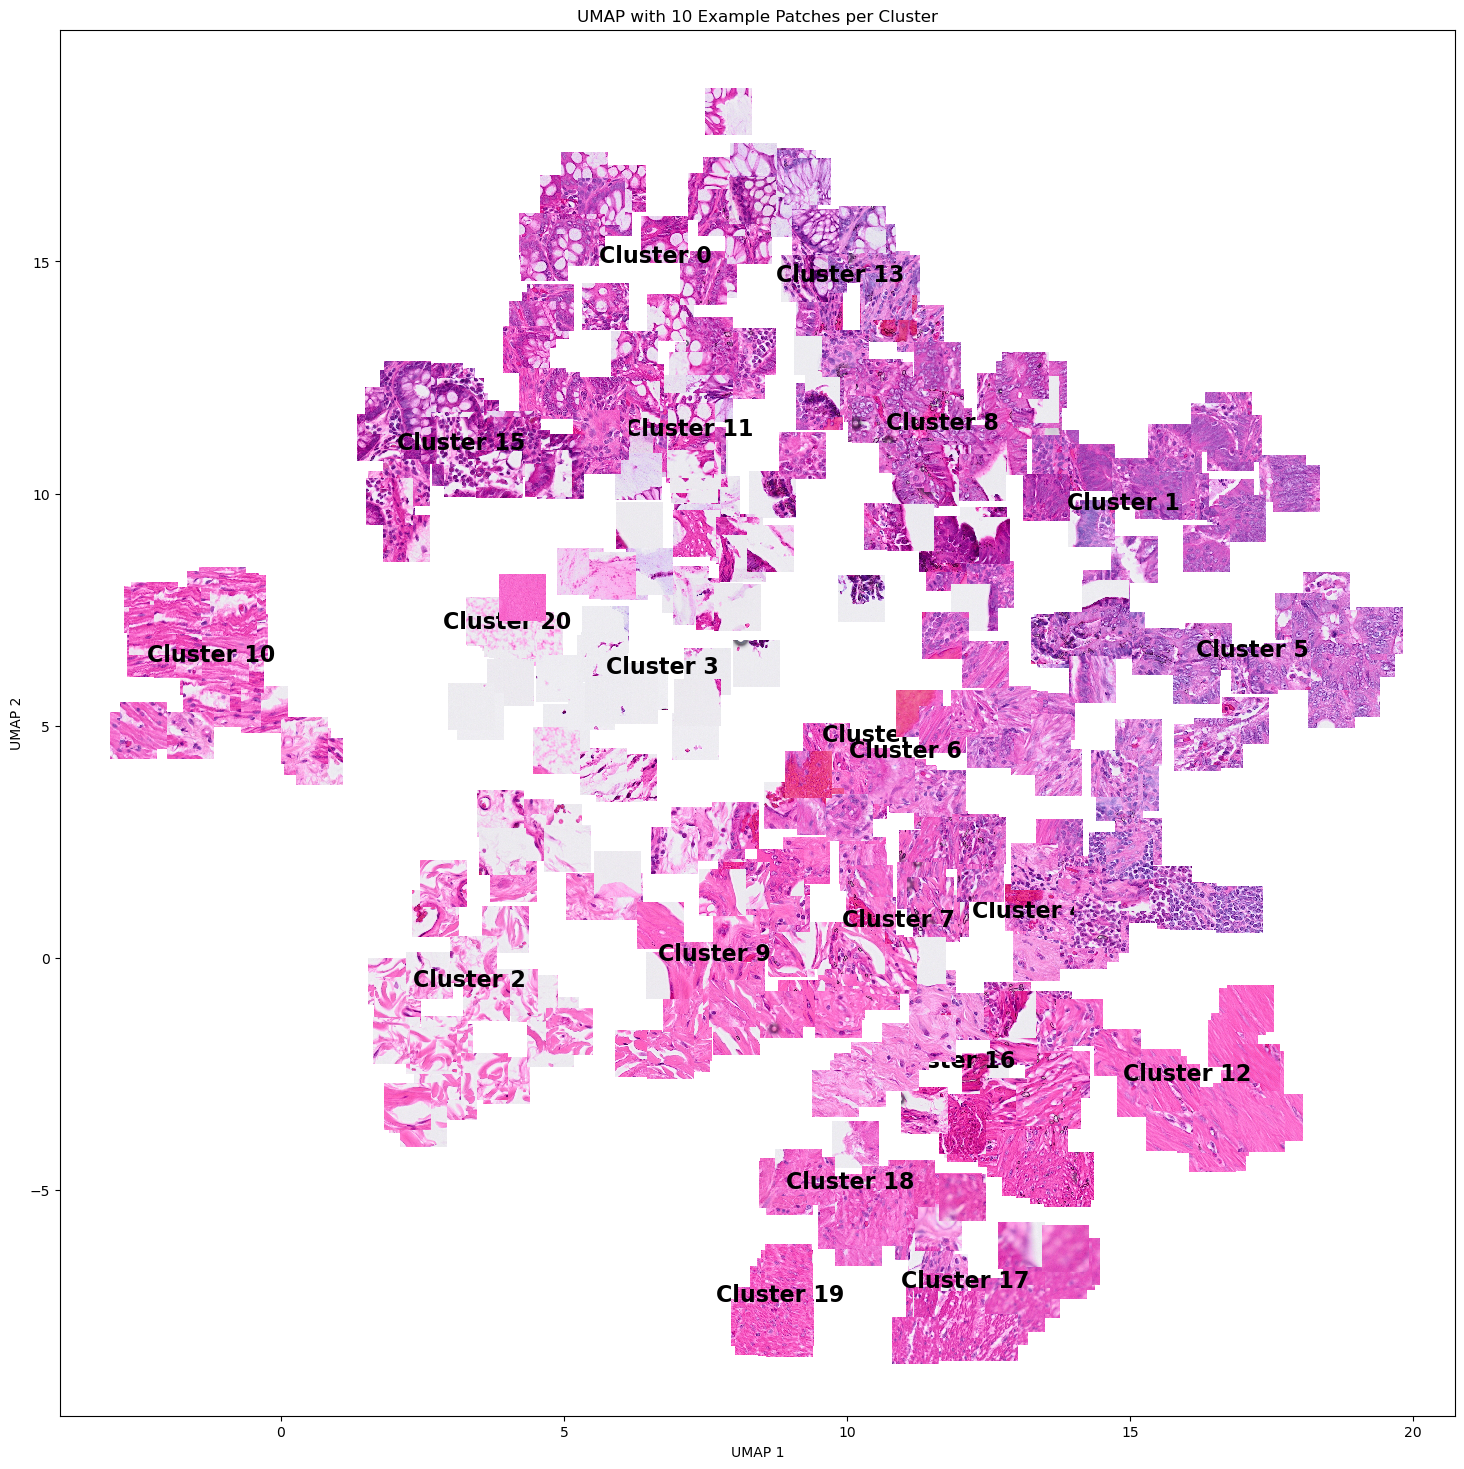

In [ ]:
new_leiden_res = 0.5 # set this to desired leiden resolution
plot_patches(adata_filter, new_leiden_res, patch_base_folder)

**IMPORTANT**: Dont forget to save the file with the cell below.

In [15]:
adata_filter.write("metadata/filtered_WSI_patch_embeddings.h5ad")

# Plotting the clusters 

In [28]:
import scanpy as sc 
import os 
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import matplotlib.patches as patches
import pandas as pd
import numpy as np

person = "CRC_P2"
cluster_col = "leiden_0.2" # cluster resolution
patch_size = 224

adata = sc.read_h5ad("metadata/filtered_WSI_patch_embeddings.h5ad")
adata = adata[adata.obs["Slide_ID"] == person]

# Extract needed info
df = adata.obs[["Slide_ID", "X", "Y", cluster_col]].copy()


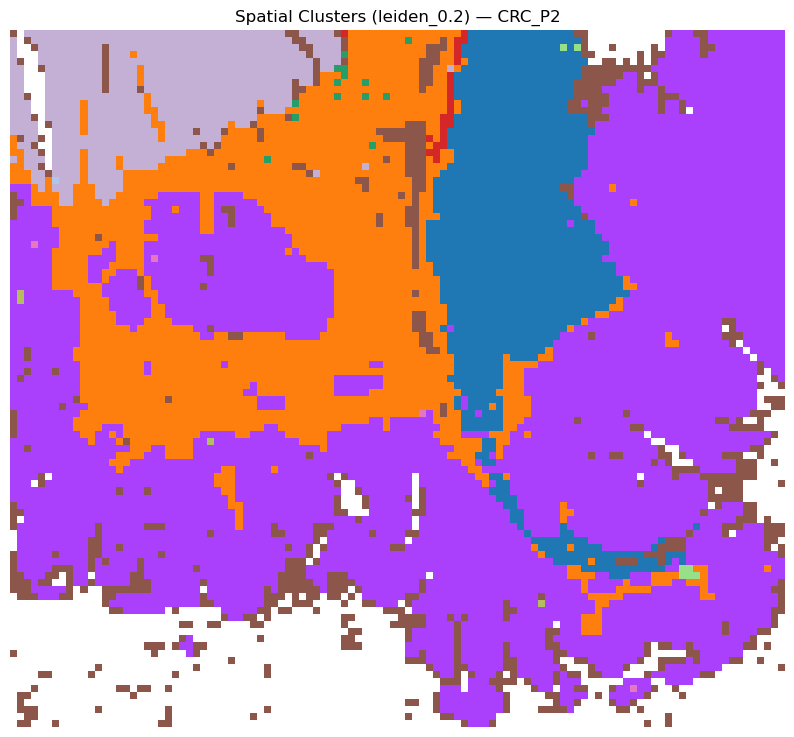

In [30]:
if f"{cluster_col}_colors" in adata.uns:
    clusters = sorted(df[cluster_col].unique(), key=lambda x: int(x))
    colors = adata.uns[f"{cluster_col}_colors"]
    color_map = {c: colors[i % len(colors)] for i, c in enumerate(clusters)}
else:
    unique_clusters = df[cluster_col].unique()
    cmap = cm.get_cmap("tab20", len(unique_clusters))
    color_map = {c: cmap(i) for i, c in enumerate(unique_clusters)}

# Create figure
fig, ax = plt.subplots(figsize=(10, 10))
ax.set_aspect('equal')
ax.set_title(f"Spatial Clusters ({cluster_col}) — {person}")

# Draw each patch as a colored rectangle
for _, row in df.iterrows():
    x, y = row["X"], row["Y"]
    color = color_map[row[cluster_col]]
    rect = patches.Rectangle(
        (x, y), patch_size, patch_size,
        facecolor=color, edgecolor='none'
    )
    ax.add_patch(rect)

# Set coordinate system: top-left = (0,0)
ax.set_xlim(df["X"].min(), df["X"].max() + patch_size)
ax.set_ylim(df["Y"].min() + patch_size, df["Y"].max())
ax.axis("off")

plt.show()